## Continuous Data Distributions

### Uniform Distribution

Analysis on Iris Dataset

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import uniform

In [2]:
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Simulating the range for sepal length column
a,b = iris['sepal_length'].min(), iris['sepal_length'].max()
a,b

(4.3, 7.9)

1. Calculate the probability density for sepal lengths in uniform distribution.

In [4]:
# Probability Density Function (PDF)
x = np.linspace(a, b, 1000)
pdf = uniform.pdf(x, loc=a, scale=b-a)
pdf[:10]

array([0.27777778, 0.27777778, 0.27777778, 0.27777778, 0.27777778,
       0.27777778, 0.27777778, 0.27777778, 0.27777778, 0.27777778])

2. What is the cumulative probability of sepal lengths being below a given value (e.g., 6)?

In [5]:
cdf = uniform.cdf(x, loc=a, scale=b-a)
cdf[:10]

array([0.        , 0.001001  , 0.002002  , 0.003003  , 0.004004  ,
       0.00500501, 0.00600601, 0.00700701, 0.00800801, 0.00900901])

3. What is the mean and variance of the uniform distribution derived from sepal lengths?

In [6]:
mean = uniform.mean(loc=a, scale=b-a)
variance = uniform.var(loc=a, scale=b-a)

print("Uniform Distribution Metrics:")
print(f"Range: [{a:.2f}, {b:.2f}]")
print(f"Mean: {mean:.2f}")
print(f"Variance: {variance:.2f}")

Uniform Distribution Metrics:
Range: [4.30, 7.90]
Mean: 6.10
Variance: 1.08


4. Visualizing the PDF & CDF for simulated sepal lengths?

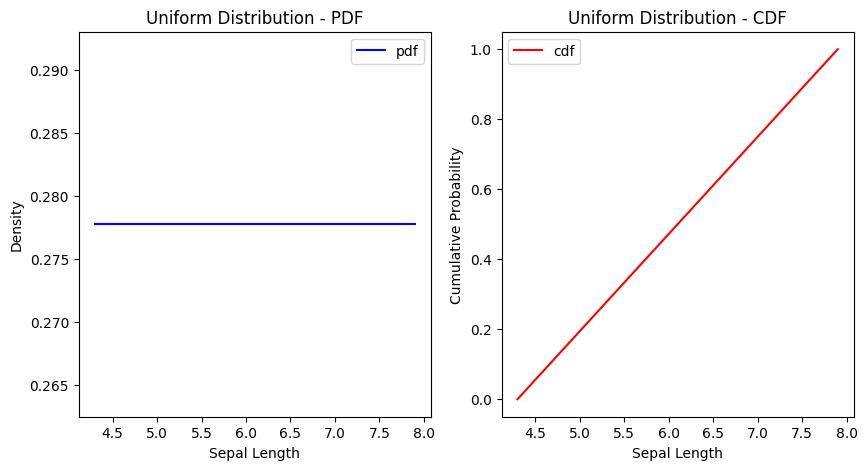

In [7]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.plot(x, pdf, label='pdf', color='blue')
plt.title('Uniform Distribution - PDF')
plt.xlabel('Sepal Length')
plt.ylabel('Density')
plt.legend()

plt.subplot(1,2,2)
plt.plot(x, cdf, label='cdf', color='red')
plt.title('Uniform Distribution - CDF')
plt.xlabel('Sepal Length')
plt.ylabel('Cumulative Probability')
plt.legend()

plt.show()


### Normal Distribution

In [9]:
from scipy.stats import norm

In [10]:
# Defining the parameters for standard normal distribution
mean, sigma = 0, 1

In [11]:
#  generating data points for PDF and CDF
x = np.linspace(mean-4*sigma, mean+4*sigma, 1000)
x[:10]

array([-4.        , -3.99199199, -3.98398398, -3.97597598, -3.96796797,
       -3.95995996, -3.95195195, -3.94394394, -3.93593594, -3.92792793])

In [12]:
pdf = norm.pdf(x, loc=mean, scale=sigma)
cdf = norm.cdf(x, loc=mean, scale=sigma)

##### Visualizing the Normal Distribution

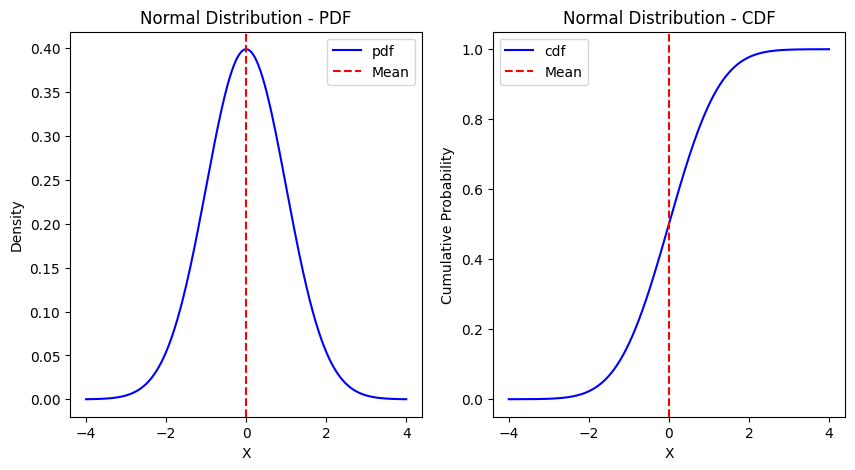

In [16]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(x, pdf, label='pdf', color='blue')
plt.axvline(mean, color='red', linestyle='--', label='Mean')
plt.title('Normal Distribution - PDF')
plt.xlabel('X')
plt.ylabel('Density')
plt.legend()

plt.subplot(1,2,2)
plt.plot(x, cdf, label='cdf', color='blue')
plt.axvline(mean, color='red', linestyle='--', label='Mean')
plt.title('Normal Distribution - CDF')
plt.xlabel('X')
plt.ylabel('Cumulative Probability')
plt.legend()

plt.show()

#### Normal Distribution Analysis on Iris Dataset

1. What are the mean and variance of the sepal width data?

In [25]:
sepal_width = iris['sepal_width']

In [26]:
mean = np.mean(sepal_width)
std_dev = np.std(sepal_width)
variance = std_dev ** 2
print(f"\nMean: {mean:.2f}, Variance: {variance:.2f}, Std Dev: {std_dev:.2f}")


Mean: 3.06, Variance: 0.19, Std Dev: 0.43


2. What is the probability of observing sepal widths below a specific value (e.g., 3.5 cm)?

In [28]:
# Probability of Observing Sepal Widths below 3.5 cm (CDF)
x = 3.5
cdf_value = norm.cdf(x, loc=mean, scale=std_dev)
print(f"\nProbability of sepal width being less than {x} cm: {cdf_value:.4f}")


Probability of sepal width being less than 3.5 cm: 0.8459


3. What is the cumulative probability of observing sepal widths above a certain value (e.g., 3.5 cm)?

In [29]:
# Cumulative Probability (CDF)
x = 3.5  # Example threshold for cumulative probability
cdf_value = 1 - norm.cdf(x, loc=mean, scale=std_dev)
print(f"\nCumulative probability of sepal width above {x} cm: {cdf_value:.4f}")


Cumulative probability of sepal width above 3.5 cm: 0.1541


4. What value of sepal width corresponds to a specific cumulative probability (e.g., 0.75)?

ppf - percentage point function (reverse of cdf)

In [30]:
# Inverse Cumulative Probability (PPF)
cumulative_prob = 0.75  # Example cumulative probability
ppf_value = norm.ppf(cumulative_prob, loc=mean, scale=std_dev)
print(f"\nSepal width corresponding to cumulative probability {cumulative_prob}: {ppf_value:.4f}")


Sepal width corresponding to cumulative probability 0.75: 3.3503


### Exponential Distribution

In [32]:
from scipy.stats import expon

In [33]:
# Parameters
lambda_rate = 0.5    # Example rate parameter (events per unit time)
size = 1000          # Number of samples

In [34]:
# Generate random samples from exponential distribution
data = np.random.exponential(scale=1/lambda_rate, size=size)

In [35]:
# PDF and CDF
x = np.linspace(0, 10, 1000)  # Range of values
pdf = expon.pdf(x, scale=1/lambda_rate)  # PDF
cdf = expon.cdf(x, scale=1/lambda_rate)  # CDF

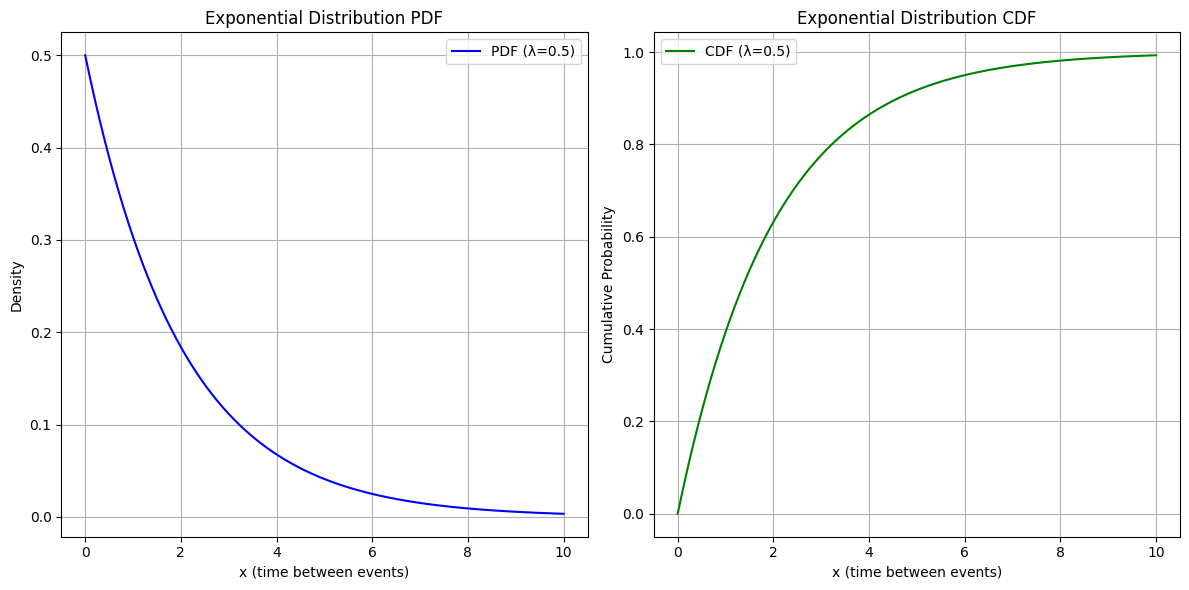

In [36]:
# Visualizing PDF
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(x, pdf, label=f'PDF (λ={lambda_rate})', color='blue')
plt.title("Exponential Distribution PDF")
plt.xlabel("x (time between events)")
plt.ylabel("Density")
plt.legend()
plt.grid()

# Visualizing CDF
plt.subplot(1, 2, 2)
plt.plot(x, cdf, label=f'CDF (λ={lambda_rate})', color='green')
plt.title("Exponential Distribution CDF")
plt.xlabel("x (time between events)")
plt.ylabel("Cumulative Probability")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

#### Let us generate real-time samples for exponential distribution

In [39]:
# Simulate Data for Time Between Arrivals
rate = 0.2             # Average rate (lambda)
scale = 1 / rate       # Scale is the inverse of the rate
size = 1000            # Number of observations

inter_arrival_times = np.random.exponential(scale=scale, size=size)
inter_arrival_times[:10]

array([8.93201721, 1.06478406, 3.40237426, 2.47504695, 1.51294329,
       5.32163882, 2.39007146, 3.24301091, 3.76490359, 1.06179932])

1. What is the average time between arrivals (mean) and its variance?

In [41]:
# Analyze the Dataset
mean = np.mean(inter_arrival_times)
variance = np.var(inter_arrival_times)

print(f"Mean Time Between Arrivals: {mean:.2f} minutes")
print(f"Variance of Time Between Arrivals: {variance:.2f} minutes")

Mean Time Between Arrivals: 5.15 minutes
Variance of Time Between Arrivals: 26.57 minutes


2. What is the probability that the next arrival occurs within 5 minutes?

In [42]:
x=5
prob_within_5 = expon.cdf(x, scale=scale)
print(f"Probability that the next arrival occurs within 5 minutes: {prob_within_5:.2f}")

Probability that the next arrival occurs within 5 minutes: 0.63


3. What is the probability that the time between arrivals exceeds 10 minutes?

In [43]:
x=10
prob_exceeds_10 = 1 - expon.cdf(10, scale=scale)
print(f"Probability that the time between arrivals exceeds 10 minutes: {prob_exceeds_10:.2f}")

Probability that the time between arrivals exceeds 10 minutes: 0.14


4. How does the shape of the distribution look, and is it consistent with an exponential distribution?

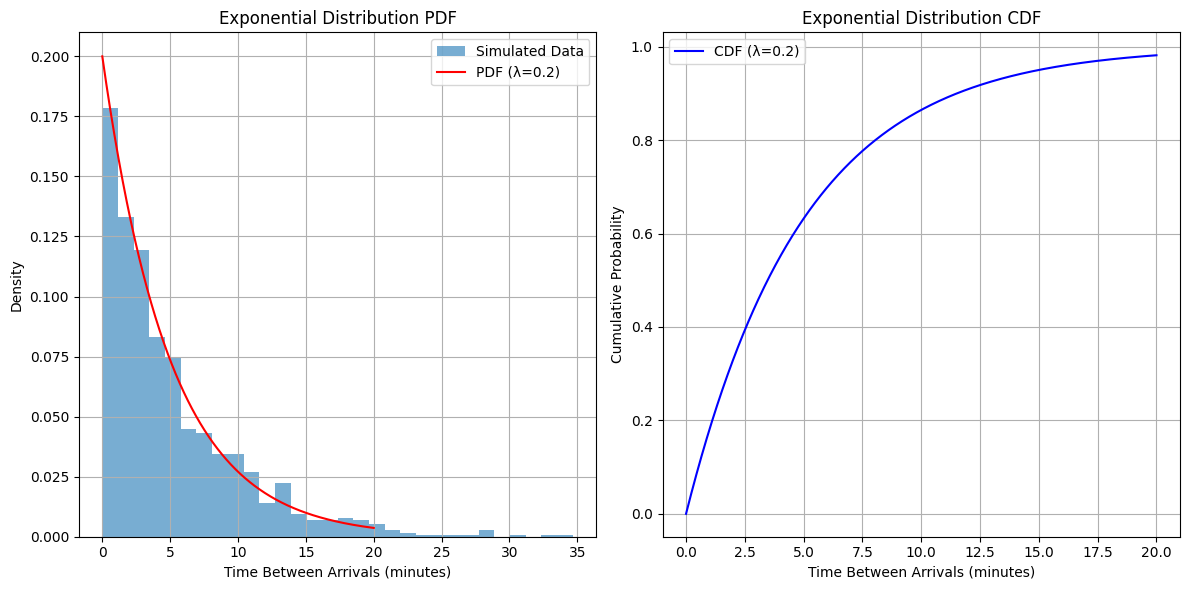

In [44]:
x = np.linspace(0, 20, 1000)
pdf = expon.pdf(x, scale=scale)
cdf = expon.cdf(x, scale=scale)

# Plot PDF and CDF
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.hist(inter_arrival_times, bins=30, density=True, alpha=0.6, label='Simulated Data')
plt.plot(x, pdf, label=f'PDF (λ={rate})', color='red')
plt.title("Exponential Distribution PDF")
plt.xlabel("Time Between Arrivals (minutes)")
plt.ylabel("Density")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(x, cdf, label=f'CDF (λ={rate})', color='blue')
plt.title("Exponential Distribution CDF")
plt.xlabel("Time Between Arrivals (minutes)")
plt.ylabel("Cumulative Probability")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Log Normal Distribution

In [46]:
from scipy.stats import lognorm

In [47]:
mu, sigma = 0, 0.954
scale = np.exp(mu)
samples = lognorm.rvs(sigma, scale=scale, size=1000)

In [48]:
x = np.linspace(min(samples), max(samples), 1000)
pdf = lognorm.pdf(x, s=sigma, scale=scale)
cdf = lognorm.cdf(x, s=sigma, scale=scale)

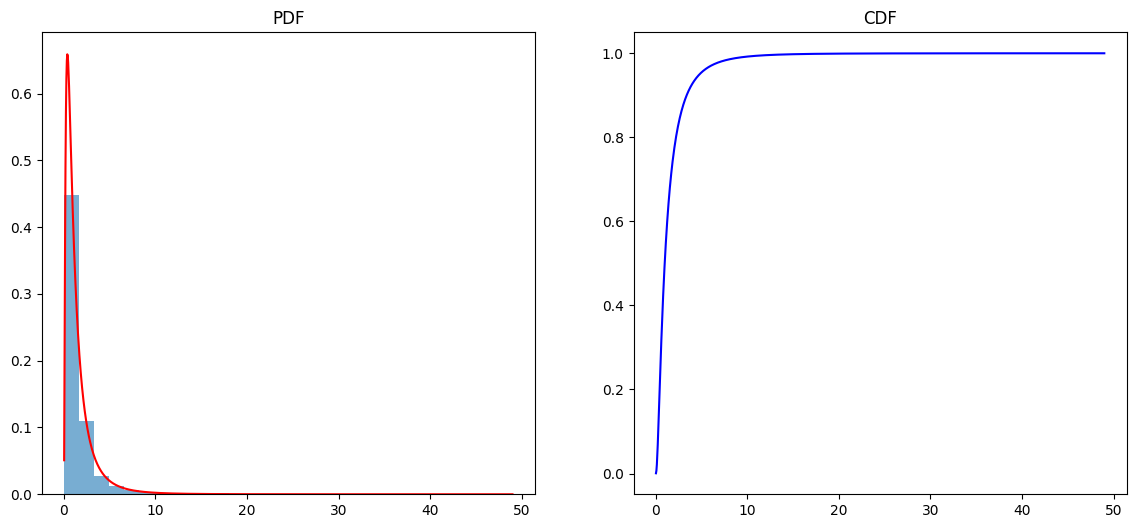

In [49]:
# Plot PDF and CDF
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.hist(samples, bins=30, density=True, alpha=0.6, label="Samples")
plt.plot(x, pdf, label="PDF", color="red")
plt.title("PDF")

plt.subplot(1, 2, 2)
plt.plot(x, cdf, label="CDF", color="blue")
plt.title("CDF")
plt.show()

#### Let us generate real-time samples for log-normal distribution

In [65]:
# Simulating a lognormal dataset
mu, sigma = 3, 0.7       # Mean and standard deviation
scale = np.exp(mu)       # Scale parameter
size = 1000              # Sample size

data_lognormal = lognorm.rvs(sigma, scale=scale, size=size)
data_lognormal[:10]

array([35.83007588, 11.96149678, 17.08568904, 35.03353596, 20.79140047,
       14.93956236, 22.37061451, 39.76822945, 39.06911899,  7.52823819])

1. What are the key statistics (mean, variance, skewness, kurtosis) of the lognormal data?

In [66]:
mean = np.mean(data_lognormal)
variance = np.var(data_lognormal)
skewness = lognorm.stats(sigma, scale=scale, moments='s')
kurtosis = lognorm.stats(sigma, scale=scale, moments='k')

print(f"Mean: {mean:.2f}, Variance: {variance:.2f}")
print(f"Skewness: {skewness:.2f}, Kurtosis: {kurtosis:.2f}")

Mean: 25.82, Variance: 378.22
Skewness: 2.89, Kurtosis: 17.79


2. What is the probability of observing a value below $50?

In [67]:
x = 50
prob_below_threshold = lognorm.cdf(x, sigma, scale=scale)
print(f"Probability of observing value below ${x}: {prob_below_threshold:.4f}")

Probability of observing value below $50: 0.9037


3. What is the probability of observing a value above $10?

In [68]:
threshold_high = 10

prob_above_threshold = 1 - lognorm.cdf(threshold_high, sigma, scale=scale)
print(f"Probability of observing value above ${threshold_high}: {prob_above_threshold:.4f}")

Probability of observing value above $10: 0.8404


4. How does the histogram and fitted PDF compare for the given lognormal data?

In [69]:
x = np.linspace(min(data_lognormal), max(data_lognormal), 1000)
pdf = lognorm.pdf(x, sigma, scale=scale)

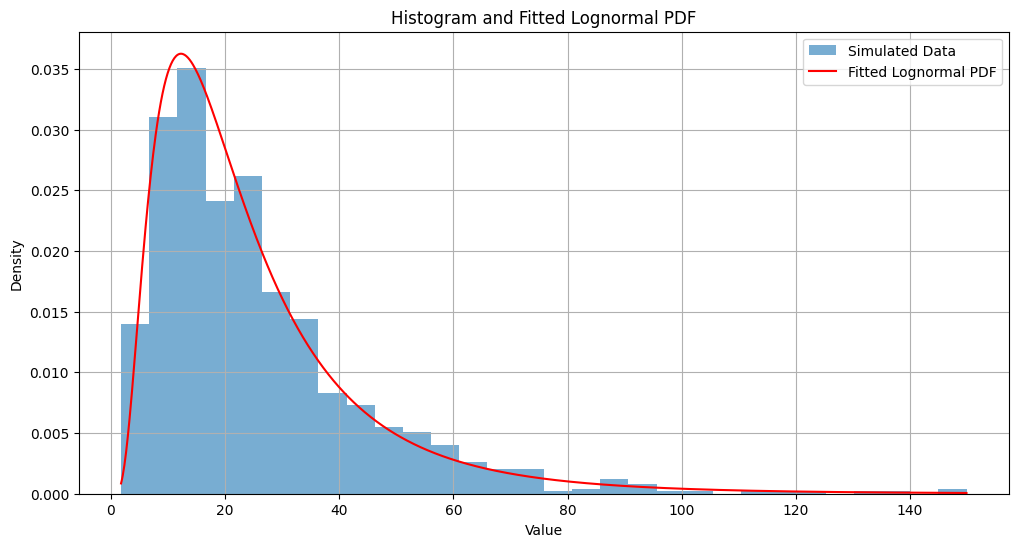

In [70]:
plt.figure(figsize=(12, 6))
plt.hist(data_lognormal, bins=30, density=True, alpha=0.6, label="Simulated Data")
plt.plot(x, pdf, label="Fitted Lognormal PDF", color="red")
plt.title("Histogram and Fitted Lognormal PDF")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()

### Pareto Distribution (Power-Law)

In [50]:
from scipy.stats import pareto

In [51]:
alpha, x_m = 2.5, 1
data = pareto.rvs(alpha, scale=x_m, size=1000)

In [52]:
x = np.linspace(min(data), max(data), 1000)
pdf = pareto.pdf(x, alpha, scale=x_m)
cdf = pareto.cdf(x, alpha, scale=x_m)

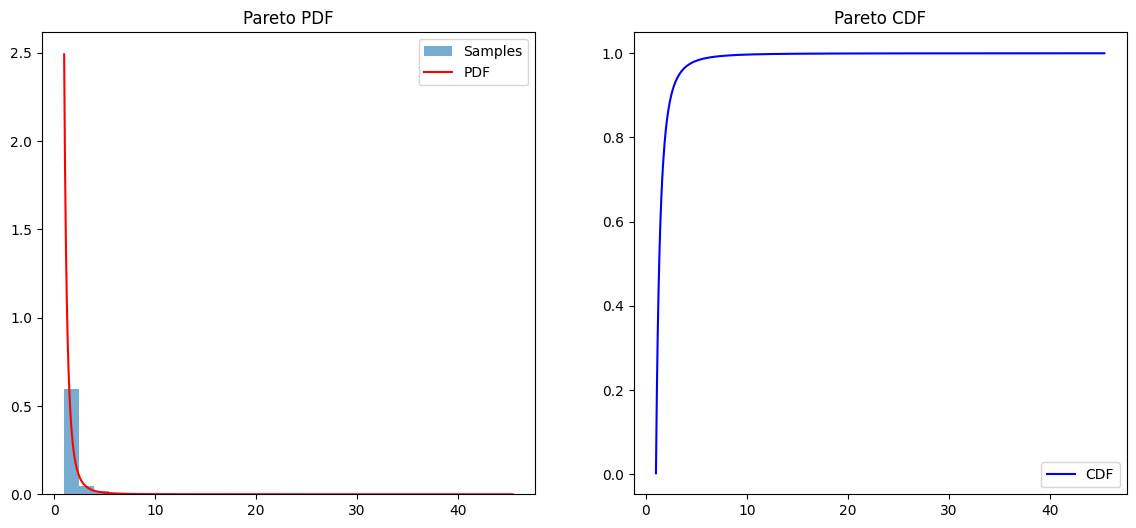

In [53]:
# Visualizing PDF & CDF
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.hist(data, bins=30, density=True, alpha=0.6, label="Samples")
plt.plot(x, pdf, label="PDF", color="red")
plt.title("Pareto PDF")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, cdf, label="CDF", color="blue")
plt.title("Pareto CDF")
plt.legend()

plt.show()

#### Let us generate real-time samples for pareto distribution

In [75]:
# Parameters
alpha = 2.5                  # Shape parameter (α)
x_m = 1                      # Minimum value (scale parameter)
size = 1000                  # Sample size

# Generate Pareto data
data_pareto = pareto.rvs(alpha, scale=x_m, size=size)

1.  What are the key descriptive statistics (mean, variance, etc.) for the dataset?

In [76]:
mean = np.mean(data_pareto)
variance = np.var(data_pareto)
skewness = pareto.stats(alpha, moments='s')
kurtosis = pareto.stats(alpha, moments='k')

print(f"Mean: {mean:.2f}")
print(f"Variance: {variance:.2f}")
print(f"Skewness: {skewness:.2f}")
print(f"Kurtosis: {kurtosis:.2f}")

Mean: 1.69
Variance: 1.56
Skewness: nan
Kurtosis: nan


2. What is the probability of an observation exceeding a certain threshold?

In [77]:
threshold = 10
prob_exceed = 1 - pareto.cdf(threshold, alpha, scale=x_m)

print(f"Probability of observation > {threshold}: {prob_exceed:.4f}")

Probability of observation > 10: 0.0032


3. What is the probability of an observation falling within a certain range (e.g., file sizes between 1 GB and 5 GB)?

In [78]:
lower_bound, upper_bound = 5, 10
prob_within_range = pareto.cdf(upper_bound, alpha, scale=x_m) - pareto.cdf(lower_bound, alpha, scale=x_m)

print(f"Probability of observation within range [{lower_bound}, {upper_bound}]: {prob_within_range:.4f}")

Probability of observation within range [5, 10]: 0.0147


4.  How does the histogram align with the fitted Pareto PDF and CDF?

In [79]:
x = np.linspace(min(data_pareto), max(data_pareto), 1000)
pdf = pareto.pdf(x, alpha, scale=x_m)
cdf = pareto.cdf(x, alpha, scale=x_m)

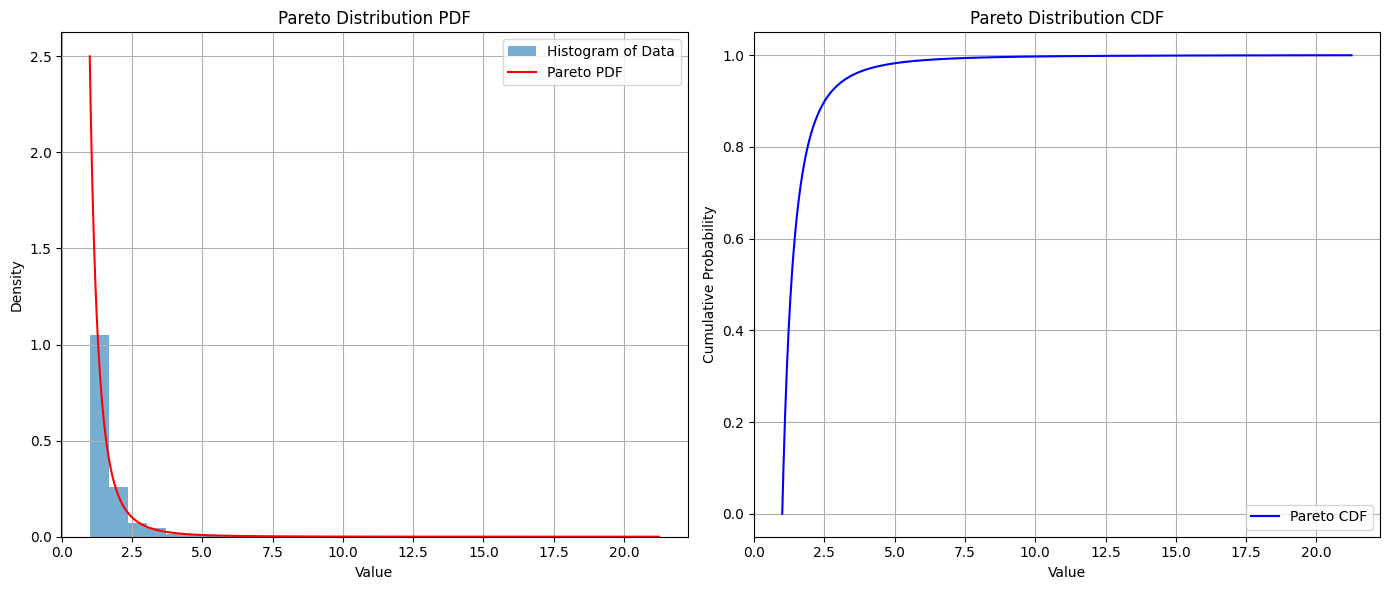

In [80]:
plt.figure(figsize=(14, 6))

# PDF plot
plt.subplot(1, 2, 1)
plt.hist(data_pareto, bins=30, density=True, alpha=0.6, label="Histogram of Data")
plt.plot(x, pdf, label="Pareto PDF", color="red")
plt.title("Pareto Distribution PDF")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.grid()

# CDF plot
plt.subplot(1, 2, 2)
plt.plot(x, cdf, label="Pareto CDF", color="blue")
plt.title("Pareto Distribution CDF")
plt.xlabel("Value")
plt.ylabel("Cumulative Probability")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()